In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')

DATA_DIR = Path('data')

df = pd.read_csv(DATA_DIR / 'marketing-campaigns-1000.csv')

In [2]:
campaign_data = (
    df
    .drop_duplicates()
    .copy()
)

In [3]:
campaign_data

,date,campaign,channel,impressions,clicks,spend,conversions,revenue
0,2025-01-01,webinar-q3,Paid Search,404717,16902,6063.52,1340,195355.15
1,2025-01-02,partner-comarketing,Affiliate,54239,1634,344.07,100,8152.24
2,2025-01-02,back-to-work,Paid Search,344142,17574,4332.83,1376,206780.02
3,2025-01-03,black-friday,Display,92848,355,439.15,4,350.47
4,2025-01-04,free-trial-push,Email,107700,12776,140.91,648,99417.63
...,...,...,...,...,...,...,...,...
995,2026-12-28,always-on-brand,Paid Search,186194,9891,3159.16,859,125606.24
996,2026-12-29,black-friday,Affiliate,302260,5418,1709.06,196,19611.56
997,2026-12-30,newsletter-growth,Display,408016,1612,1322.91,16,1197.68
998,2026-12-30,black-friday,Paid Social,392278,3669,3627.43,43,3344.60


In [4]:
campaign_data['date'] = pd.to_datetime(campaign_data['date'])
campaign_data['year'] = campaign_data['date'].dt.year
campaign_data['month'] = campaign_data['date'].dt.month
campaign_data['year_month'] = campaign_data['date'].dt.to_period('M')

print(campaign_data['date'].min())
print(campaign_data['date'].max())

2025-01-01 00:00:00
2026-12-31 00:00:00


In [5]:
#每月趨勢


monthly = (
    campaign_data.groupby('year_month')
    .agg({
        'impressions':'sum',
        'clicks':'sum',
        'spend':'sum',
        'conversions':'sum',
        'revenue':'sum'
    })
    .reset_index()
)


monthly['ctr'] = (
    monthly['clicks']
    .div(monthly['impressions'])
    .where(monthly['impressions'] > 0 )
)

monthly['cvr'] = (
    monthly['conversions']
    .div(monthly['clicks'])
    .where(monthly['clicks'] > 0 )
)

monthly['cpa'] = (
    monthly['spend']
    .div(monthly['conversions'])
    .where(monthly['conversions'] > 0 )
)


monthly['roas'] = (
    monthly['revenue']
    .div(monthly['spend'])
    .where(monthly['spend'] > 0 )
)

monthly

,year_month,impressions,clicks,spend,conversions,revenue,ctr,cvr,cpa,roas
0,2025-01,9704003,266406,75342.70,17229,2162250.56,0.027453,0.064672,4.373016,28.698873
1,2025-02,8381049,340036,74501.30,21303,2901340.71,0.040572,0.062649,3.497221,38.943491
2,2025-03,10211378,302290,92262.09,17193,2473269.43,0.029603,0.056876,5.366259,26.806995
3,2025-04,11259483,362050,91474.81,18921,2882973.51,0.032155,0.052261,4.834565,31.516584
4,2025-05,11361804,416293,83762.69,25968,3848350.60,0.036640,0.062379,3.225612,45.943493
5,2025-06,10608008,311055,75339.13,21175,3043937.82,0.029323,0.068075,3.557928,40.403145
6,2025-07,9210752,268049,72293.10,13863,2008982.10,0.029102,0.051718,5.214824,27.789403
7,2025-08,8567962,336847,61794.21,22605,2873106.62,0.039315,0.067108,2.733652,46.494754
8,2025-09,10618435,290900,79479.06,16264,2027709.92,0.027396,0.055909,4.886809,25.512505
9,2025-10,11886370,351473,96196.23,24034,3279480.35,0.029569,0.068381,4.002506,34.091568


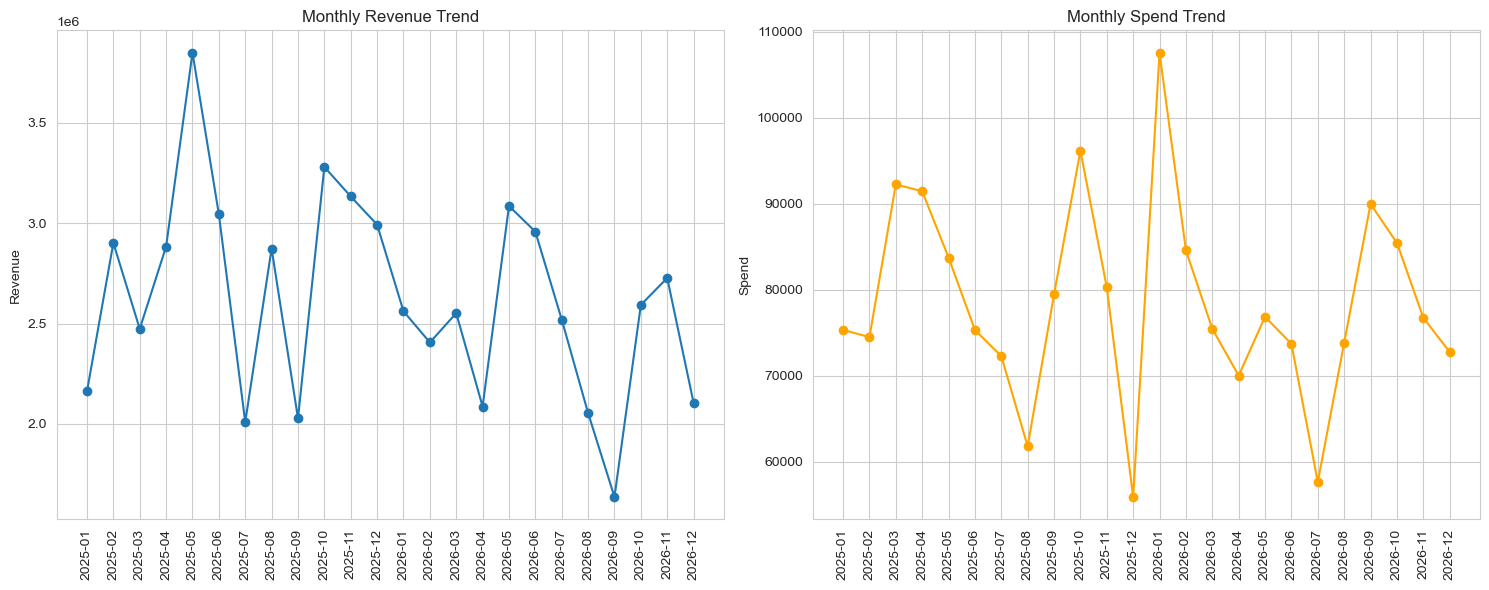

In [6]:
fig, axes = plt.subplots(1, 2, figsize = (15, 6))

x = monthly['year_month'].astype(str)

axes[0].plot(x, monthly['revenue'], marker = 'o')
axes[0].set_title('Monthly Revenue Trend')
axes[0].set_ylabel('Revenue')
axes[0].tick_params(axis= 'x', rotation = 90)


axes[1].plot(x, monthly['spend'], marker = 'o', color = 'orange')
axes[1].set_title('Monthly Spend Trend')
axes[1].set_ylabel('Spend')
axes[1].tick_params(axis= 'x', rotation = 90)

plt.tight_layout()
plt.show()


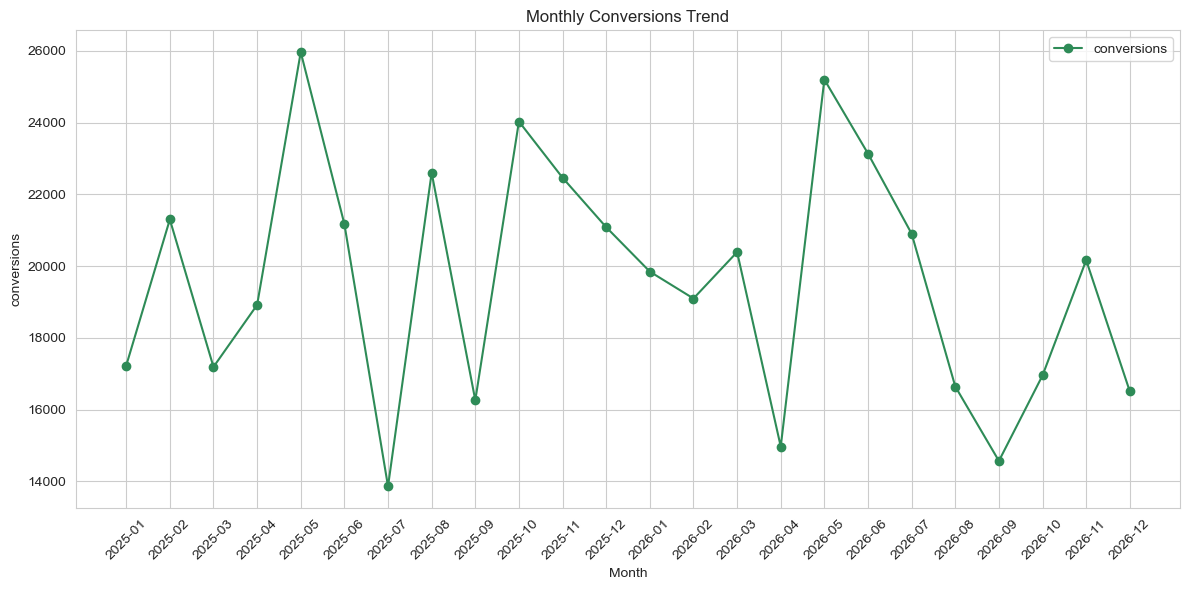

In [7]:
plt.figure(figsize = (12,6))

plt.plot(
    monthly['year_month'].astype(str),
    monthly['conversions'],
    marker = 'o',
    color = 'seagreen',
    label = 'conversions'
)

plt.xticks(rotation = 45)
plt.title('Monthly Conversions Trend')
plt.xlabel('Month')
plt.ylabel('conversions')
plt.legend()
plt.tight_layout()
plt.show()



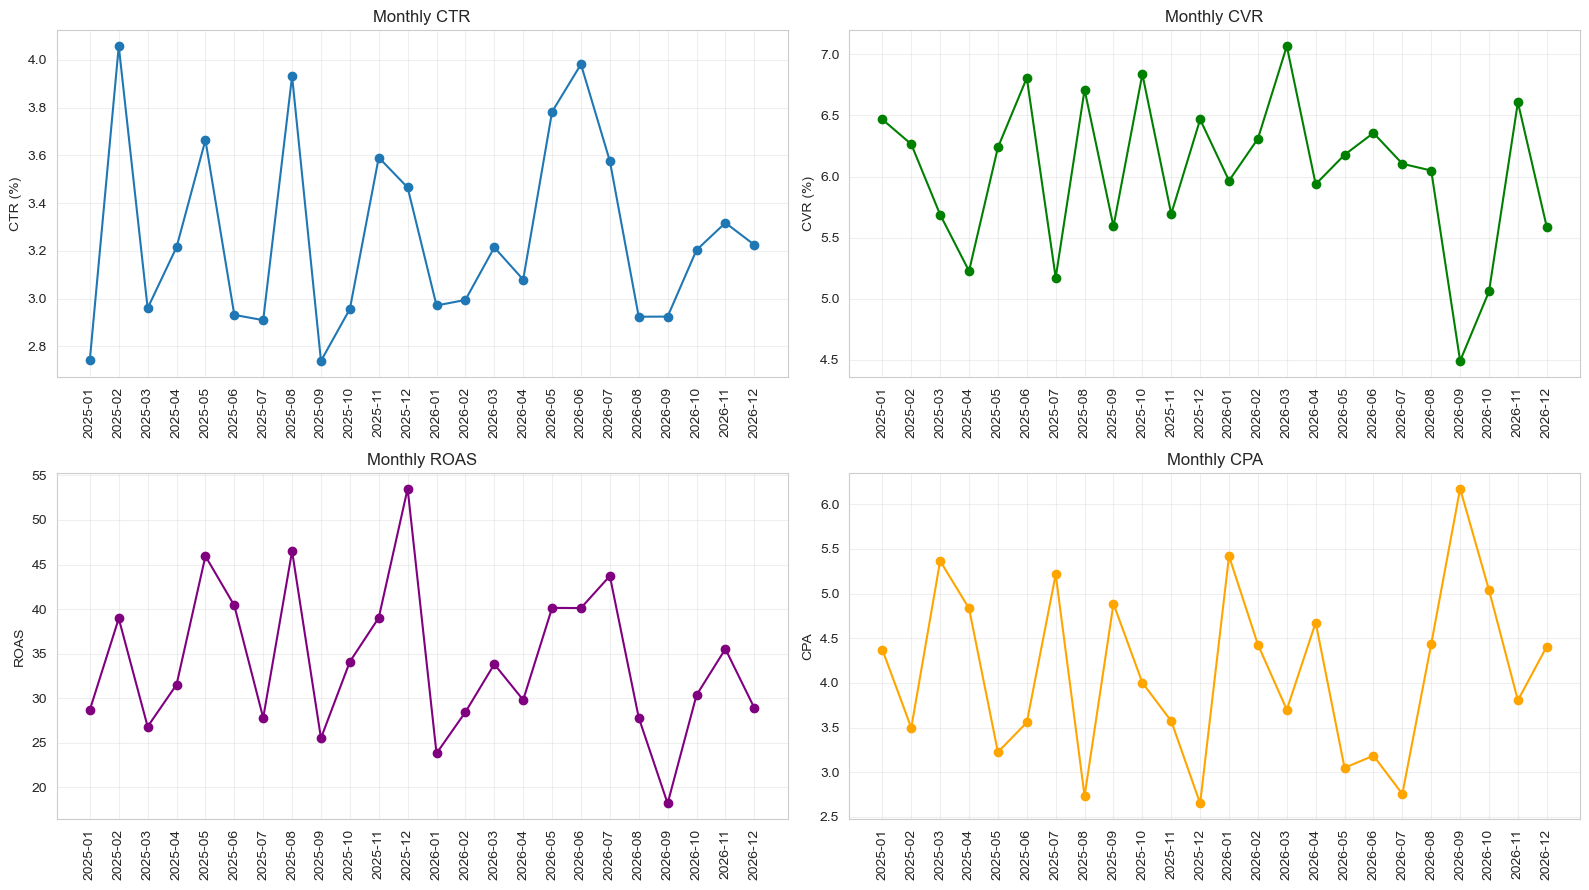

In [24]:
fig, axes = plt.subplots(2, 2, figsize = (16, 9))

x = monthly['year_month'].astype(str)

axes[0, 0].plot(x, monthly['ctr'] * 100, marker = 'o')
axes[0, 0].set_title('Monthly CTR')
axes[0, 0].set_ylabel('CTR (%)')

axes[0, 1].plot(x, monthly['cvr'] * 100, marker = 'o' , color = 'green')
axes[0, 1].set_title('Monthly CVR')
axes[0, 1].set_ylabel('CVR (%)')

axes[1, 0].plot(x, monthly['roas'], marker = 'o' , color = 'purple')
axes[1, 0].set_title('Monthly ROAS')
axes[1, 0].set_ylabel('ROAS')

axes[1, 1].plot(x, monthly['cpa'] , marker = 'o' , color = 'orange')
axes[1, 1].set_title('Monthly CPA')
axes[1, 1].set_ylabel('CPA')

for ax in axes.flat:
    ax.tick_params(axis = 'x', rotation = 90)
    ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

In [9]:
yearly = (
    campaign_data.groupby('year')
    .agg({
        'impressions':'sum',
        'clicks':'sum',
        'spend':'sum',
        'conversions':'sum',
        'revenue':'sum'
        })
        .reset_index()
)

yearly['ctr'] = yearly['clicks'] / yearly['impressions']
yearly['cvr'] = yearly['conversions'] / yearly['clicks']
yearly['cpa'] = yearly['spend'] / yearly['conversions']
yearly['roas'] = yearly['revenue'] / yearly['spend']

yearly

,year,impressions,clicks,spend,conversions,revenue,ctr,cvr,cpa,roas
0,2025,122206663,3966069,938635.29,242110,33625855.33,0.032454,0.061045,3.876896,35.824197
1,2026,117307619,3826460,944725.27,228420,29281814.00,0.032619,0.059695,4.135913,30.995057


In [10]:
year_2025 = yearly[yearly['year'] == 2025].iloc[0]
year_2026 = yearly[yearly['year'] == 2026].iloc[0]

comparison = pd.DataFrame({
    'metric': ['revenue', 'spend', 'conversions', 'ctr', 'cvr', 'cpa', 'roas'],
    '2025': [
        year_2025['revenue'],
        year_2025['spend'],
        year_2025['conversions'],
        year_2025['ctr'],
        year_2025['cvr'],
        year_2025['cpa'],
        year_2025['roas']
    ],
    '2026': [
        year_2026['revenue'],
        year_2026['spend'],
        year_2026['conversions'],
        year_2026['ctr'],
        year_2026['cvr'],
        year_2026['cpa'],
        year_2026['roas']
    ]
})

comparison['growth_rate'] = (
    comparison['2026'] / comparison['2025'] - 1
) * 100

comparison

,metric,2025,2026,growth_rate
0,revenue,3.362586e+07,2.928181e+07,-12.918753
1,spend,9.386353e+05,9.447253e+05,0.648812
2,conversions,2.421100e+05,2.284200e+05,-5.654455
3,ctr,3.245379e-02,3.261902e-02,0.509145
4,cvr,6.104533e-02,5.969486e-02,-2.212242
5,cpa,3.876896e+00,4.135913e+00,6.681043
6,roas,3.582420e+01,3.099506e+01,-13.480105


In [11]:
may_2025 = campaign_data[campaign_data['year_month'] == pd.Period('2025-05')].copy()

In [12]:
may_summary = may_2025.agg({
    'impressions': 'sum',
    'clicks': 'sum',
    'spend': 'sum',
    'conversions': 'sum',
    'revenue': 'sum'
})

may_summary

impressions    11361804.00
clicks           416293.00
spend             83762.69
conversions       25968.00
revenue         3848350.60
dtype: float64

In [13]:
may_ctr = may_summary['clicks'] *100 / may_summary['impressions']
may_cvr = may_summary['conversions'] *100 / may_summary['clicks']
may_cpa = may_summary['spend'] / may_summary['conversions']
may_roas = may_summary['revenue'] / may_summary['spend']

print('CTR:', may_ctr)
print('CVR:', may_cvr)
print('CPA:', may_cpa)
print('ROAS:', may_roas)

CTR: 3.6639692077068045
CVR: 6.237914161419962
CPA: 3.2256119069624147
ROAS: 45.943493457528646


In [14]:
def summarize_performance(data, group_by):
    summary = (
        data.groupby(group_by)
            .agg({
                'impressions': 'sum',
                'clicks': 'sum',
                'spend': 'sum',
                'conversions': 'sum',
                'revenue': 'sum'
            })
            .reset_index()
    )

    summary['ctr'] = (
        summary['clicks'] *100 / summary['impressions']
    )

    summary['cvr'] = (
        summary['conversions'] *100 / summary['clicks']
    )

    summary['cpa'] = (
        summary['spend'] / summary['conversions']
    )

    summary['roas'] = (
        summary['revenue'] / summary['spend']
    )

    summary['revenue_share'] = (
        summary['revenue'] * 100 / summary['revenue'].sum()
    ) 

    summary['spend_share'] = (
        summary['spend'] * 100 / summary['spend'].sum()
    )

    return summary

In [15]:
#渠道分析

may_channel = summarize_performance(
    may_2025,
    'channel'
)

may_channel.sort_values('revenue', ascending = False)

,channel,impressions,clicks,spend,conversions,revenue,ctr,cvr,cpa,roas,revenue_share,spend_share
2,Email,2732581,236673,3477.15,16609,2753385.16,8.661152,7.017700,0.209353,791.851131,71.547150,4.151192
3,Paid Search,2867728,111985,40502.87,6790,811881.74,3.905008,6.063312,5.965077,20.045042,21.096876,48.354309
0,Affiliate,1172210,33213,7849.25,1869,204740.03,2.833366,5.627315,4.199706,26.084025,5.320202,9.370819
4,Paid Social,1798537,23046,16666.69,584,66931.93,1.281375,2.534062,28.538853,4.015910,1.739237,19.897510
5,Video,530119,3828,6305.81,56,6341.25,0.722102,1.462905,112.603750,1.005620,0.164778,7.528185
1,Display,2260629,7548,8960.92,60,5070.49,0.333889,0.794913,149.348667,0.565845,0.131757,10.697985


In [16]:
# campaign 分析

may_campaign = summarize_performance(
    may_2025,
    'campaign'
)

may_campaign.sort_values('revenue', ascending = False).head(10)


,campaign,impressions,clicks,spend,conversions,revenue,ctr,cvr,cpa,roas,revenue_share,spend_share
1,back-to-work,1656835,83519,6472.24,5274,675570.71,5.040876,6.314731,1.227198,104.379737,17.554812,7.726877
0,always-on-brand,904094,55700,4672.93,3991,669464.15,6.160864,7.165171,1.170867,143.264322,17.396132,5.578773
3,case-study-promo,803997,42781,4044.42,3795,654436.01,5.321040,8.870760,1.065723,161.812079,17.005623,4.828427
10,winback-lapsed,1345186,43876,13025.27,2833,471892.85,3.261705,6.456833,4.597695,36.229026,12.262210,15.550205
8,spring-launch,838723,52193,6316.99,3190,466053.70,6.222913,6.111931,1.980248,73.777812,12.110479,7.541532
4,developer-outreach,1075775,57607,8331.73,2964,393148.77,5.354930,5.145208,2.810975,47.186931,10.216033,9.946827
6,newsletter-growth,1287544,29775,12955.36,1703,246570.54,2.312542,5.719563,7.607375,19.032319,6.407175,15.466743
9,webinar-q3,917525,14288,7442.28,875,117210.21,1.557233,6.124020,8.505463,15.749234,3.045726,8.884958
5,free-trial-push,747406,15737,5053.90,820,102895.57,2.105549,5.210650,6.163293,20.359637,2.673758,6.033593
7,partner-comarketing,915542,12270,6592.21,389,35834.92,1.340190,3.170334,16.946555,5.435949,0.931176,7.870103


In [17]:
#campaign x channel 分析

may_campaign_channel = summarize_performance(
    may_2025,
    ['campaign', 'channel']
)

may_campaign_channel.sort_values('revenue', ascending = False).head(10)

,campaign,channel,impressions,clicks,spend,conversions,revenue,ctr,cvr,cpa,roas,revenue_share,spend_share
9,case-study-promo,Email,363734,32312,490.36,3304,601643.88,8.883415,10.225303,0.148414,1226.943225,15.633812,0.585416
4,back-to-work,Email,881878,68714,1190.62,4599,595960.24,7.791781,6.692959,0.258887,500.546136,15.486121,1.421420
1,always-on-brand,Email,420405,44232,591.65,3265,591401.32,10.521283,7.381534,0.181210,999.579684,15.367657,0.706341
23,spring-launch,Email,419315,34117,416.65,2418,400341.74,8.136365,7.087376,0.172312,960.858610,10.402944,0.497417
29,winback-lapsed,Email,324734,23941,431.68,1835,360334.46,7.372496,7.664676,0.235248,834.725862,9.363348,0.515361
17,newsletter-growth,Paid Search,726694,26245,9639.11,1651,241050.07,3.611561,6.290722,5.838346,25.007503,6.263724,11.507641
12,developer-outreach,Email,322515,33357,356.19,1188,203703.52,10.342775,3.561471,0.299823,571.895674,5.293268,0.425237
13,developer-outreach,Paid Search,567879,23483,7201.05,1770,189076.00,4.135212,7.537367,4.068390,26.256726,4.913170,8.596966
14,free-trial-push,Affiliate,673016,15350,4725.30,818,102783.12,2.280778,5.328990,5.776650,21.751660,2.670836,5.641294
27,webinar-q3,Paid Search,317232,8644,4784.23,671,99658.32,2.724820,7.762610,7.130000,20.830587,2.589637,5.711648


In [18]:
sep_2026 = campaign_data[campaign_data['year_month'] == pd.Period('2026-09')].copy()

In [19]:
sep_2026_summary = sep_2026.agg({
    'impressions': 'sum',
    'clicks': 'sum',
    'spend': 'sum',
    'conversions': 'sum',
    'revenue': 'sum'
})

sep_2026_summary


impressions    11095123.00
clicks           324548.00
spend             89992.13
conversions       14572.00
revenue         1636782.80
dtype: float64

In [25]:
sep_2026_ctr = sep_2026_summary['clicks'] *100 / sep_2026_summary['impressions']
sep_2026_cvr = sep_2026_summary['conversions'] *100 / sep_2026_summary['clicks']
sep_2026_cpa = sep_2026_summary['spend'] / sep_2026_summary['conversions']
sep_2026_roas = sep_2026_summary['revenue'] / sep_2026_summary['spend']

print('CTR:', sep_2026_ctr)
print('CVR:', sep_2026_cvr)
print('CPA:', sep_2026_cpa)
print('ROAS:', sep_2026_roas)

CTR: 2.9251410732445238
CVR: 4.489936773605137
CPA: 6.175688306340928
ROAS: 18.18806600088252


In [21]:
#渠道分析

sep_2026_channel = summarize_performance(
    sep_2026,
    'channel'
)

sep_2026_channel.sort_values('revenue', ascending = False)

,channel,impressions,clicks,spend,conversions,revenue,ctr,cvr,cpa,roas,revenue_share,spend_share
2,Email,747839,83202,1082.47,4500,564424.87,11.125657,5.408524,0.240549,521.423106,34.483798,1.202850
0,Affiliate,2466535,81532,14051.14,4567,490583.81,3.305528,5.601482,3.076667,34.914164,29.972444,15.613743
3,Paid Search,2275956,109739,31927.25,4579,489349.31,4.821666,4.172628,6.972538,15.327011,29.897022,35.477825
4,Paid Social,2031487,31397,20641.69,714,67495.12,1.545518,2.274103,28.909930,3.269845,4.123645,22.937217
5,Video,864241,8444,11114.16,142,18562.23,0.977042,1.681667,78.268732,1.670142,1.134068,12.350147
1,Display,2709065,10234,11175.42,70,6367.46,0.377769,0.683995,159.648857,0.569774,0.389023,12.418219


In [22]:
#campaign 分析

sep_2026_campaign = summarize_performance(
    sep_2026,
    'campaign'
)

sep_2026_campaign.sort_values('revenue', ascending = False)

,campaign,impressions,clicks,spend,conversions,revenue,ctr,cvr,cpa,roas,revenue_share,spend_share
1,back-to-work,650213,40618,6325.29,2615,331589.00,6.246876,6.438032,2.418849,52.422735,20.258583,7.028715
7,partner-comarketing,830861,70084,7691.42,3056,330082.24,8.435105,4.360482,2.516826,42.915644,20.166527,8.546770
6,newsletter-growth,2254250,40739,15127.71,1890,237701.73,1.807209,4.639289,8.004079,15.713002,14.522497,16.810037
8,retargeting-cart,1240811,36455,11537.48,1662,193749.10,2.937998,4.559045,6.941925,16.793017,11.837191,12.820543
3,case-study-promo,1483227,35250,17029.94,1501,172871.77,2.376575,4.258156,11.345730,10.151050,10.561681,18.923810
5,free-trial-push,668928,24112,3517.82,1444,123208.32,3.604573,5.988719,2.436163,35.024055,7.527469,3.909031
11,winback-lapsed,1011931,17862,5251.27,831,98436.23,1.765140,4.652335,6.319218,18.745224,6.014007,5.835255
0,always-on-brand,1013596,30997,11660.98,796,67285.06,3.058122,2.567990,14.649472,5.770103,4.110812,12.957778
2,black-friday,643116,9625,5679.57,305,32712.90,1.496620,3.168831,18.621541,5.759749,1.998610,6.311185
9,spring-launch,294940,12241,1482.55,279,24977.71,4.150336,2.279226,5.313799,16.847803,1.526025,1.647422


In [23]:
#campaign x channel 分析

sep_2026_campaign_channel = summarize_performance(
    sep_2026,
    ['campaign', 'channel']
)

sep_2026_campaign_channel.sort_values('revenue', ascending = False).head(10)

,campaign,channel,impressions,clicks,spend,conversions,revenue,ctr,cvr,cpa,roas,revenue_share,spend_share
3,back-to-work,Email,246288,17642,341.61,1930,271087.72,7.163159,10.939803,0.177000,793.559088,16.562229,0.379600
20,partner-comarketing,Email,396018,54476,585.05,1864,207046.07,13.755940,3.421690,0.313868,353.894659,12.649575,0.650112
15,newsletter-growth,Affiliate,433572,16526,2547.40,1155,146513.81,3.811593,6.988987,2.205541,57.515039,8.951329,2.830692
14,free-trial-push,Affiliate,668928,24112,3517.82,1444,123208.32,3.604573,5.988719,2.436163,35.024055,7.527469,3.909031
21,partner-comarketing,Paid Search,434843,15608,7106.37,1192,123036.17,3.589341,7.637109,5.961720,17.313505,7.516952,7.896657
22,retargeting-cart,Affiliate,458253,17131,2669.94,1066,118322.24,3.738328,6.222637,2.504634,44.316442,7.228952,2.966859
9,case-study-promo,Paid Search,465546,21645,5955.46,1031,116793.19,4.649379,4.763225,5.776392,19.611111,7.135534,6.617756
29,winback-lapsed,Email,105533,11084,155.81,706,86291.08,10.502876,6.369542,0.220694,553.822476,5.271993,0.173137
17,newsletter-growth,Paid Search,312006,16621,4181.32,662,83437.11,5.327141,3.982913,6.316193,19.954730,5.097629,4.646317
4,back-to-work,Paid Search,403925,22976,5983.68,685,60501.28,5.688185,2.981372,8.735299,10.111049,3.696354,6.649115
